In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Summary

1. Matabolic similarity

    Similar N utilization pathways => similar transcriptional response?
2. Regulatory divergence

    If two N sources share a lot of matabolic reactions, but have different iModulon activity profiles. The difference can be expained by what regulatory modules? 

    iModulon activity profile change does't mean TRN rewiring.

- Heatmap

    Sharing the nitrogen pathway but not necessaryly have similar iModulon activity profiles. Metabolis pathway can explain part of transcriptional similarity, bit it is not the only factor.

    e.g. Sharing the down stream pathway, but different upstream regulation. L-Ornithine -> Putrescine -> GABA, Putrescine needs uptake and degrade system, while GABA can enter the GABA catabolism directly. Regulations are different.

    iModulon may reflex the status of using this N, not only the pathways.

    Activity doesn't mean matabolic flux

    Even fix the C source, still affect carbon metabolism





In [3]:
iModulons = pd.read_csv("iModulons.csv", header=0)
imodulon_dict = {
    modulon: set(iModulons.loc[iModulons[modulon] == 1, iModulons.columns[0]])
    for modulon in iModulons.columns[1:]
}  # iModulon: (genes)

gene_modulon_dict = {
    row[iModulons.columns[0]]: {
        modulon
        for modulon in iModulons.columns[1:]
        if row[modulon] == 1
    }
    for _, row in iModulons.iterrows()
    if row[iModulons.columns[1:]].sum() > 0
}# gene: (iMoludons it involves)

In [39]:
gene_info = pd.read_csv("precise_mg1655-gene_info.csv")

In [5]:
tpm = pd.read_csv("precise_mg1655-log_tpm.csv", header=0)
samples = pd.read_csv("precise_mg1655-sample_table.csv", header=0)

def filter_tpm_by_metadata(filtered_metadata, tpm_table = tpm):
    """
    Filter TPM expression table using unique_identifier
    from a filtered metadata dataframe.

    Parameters
    ----------
    filtered_metadata : pd.DataFrame
        Filtered sample metadata containing unique_identifier.

    tpm_table : pd.DataFrame
        Gene expression table:
        rows = genes
        columns = sample unique_identifiers.

    Returns
    -------
    pd.DataFrame
        TPM table containing gene_id + selected samples.
    """

    # Get filtered sample IDs
    sample_ids = (filtered_metadata["unique_identifier"].tolist())

    # Keep only IDs that actually exist in TPM table
    valid_ids = [sample_id for sample_id in sample_ids if sample_id in tpm_table.columns
    ]

    # Check missing IDs
    missing_ids = [sample_id for sample_id in sample_ids if sample_id not in tpm_table.columns]

    if missing_ids:
        print("Warning: IDs not found in TPM table:")
        print(missing_ids)

    # first column = gene_id, rest columns = selected samples
    gene_col = tpm_table.columns[0]

    # gene_id + selected samples
    filtered_tpm = tpm_table[[gene_col] + valid_ids].copy()
    filtered_tpm = filtered_tpm.set_index(gene_col)
    return filtered_tpm

In [6]:
A_matrix = pd.read_csv("precise_mg1655-A.csv", header=0)
A_matrix = A_matrix[A_matrix.columns.drop("imodulon_k")]
A_matrix.set_index("imodulon_name", inplace=True)

In [7]:
# nitrogen_df, Glucose_<N source>
nitrogen_df = samples[
    (samples["project"] == "SNPv1")
    & (samples["condition"].str.startswith(("Glucose_", "D-Glucose_"), na=False))
].copy()

## PCA

In [8]:
categories = {
    "Ammonium": ["NH4Cl(1)"],

    "Amino acids": [
        "L-Alanine(1)", "D-Alanine(1)", "L-Asparagine(1)",
        "L-Aspartic_acid(1)", "L-Cysteine(1)", "Glycine(1)",
        "L-Serine(1)", "L-Proline(1)"],

    "Arginine–Ornithine–Putrescine–GABA": ["L-Arginine(1)", "L-Ornithine(1)", "Putrescine(1)", "g-Amino-N-Butyric_acid(1)"],

    "Purines": ["Adenine(1)", "Adenosine(1)"],

    "Pyrimidines": ["Cytidine(1)", "Cytosine(1)"],
    
    "Amino sugars": ["N-Acetyl-Neuraminic_acid(1)", "N-Acetyl-D-Glucosamine(1)"]
}

source_to_category = {
    source: category
    for category, sources in categories.items()
    for source in sources
}

In [1]:
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
A_normalized = pd.DataFrame(
    scaler.fit_transform(A_matrix.T).T,
    index=A_matrix.index,
    columns=A_matrix.columns
)

# Samples × iModulons
X = A_normalized[nitrogen_df["unique_identifier"].to_list()].T

pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

# Add nitrogen source metadata
metadata = nitrogen_df.set_index("unique_identifier")

pca_df["N_source"] = metadata.loc[
    pca_df.index, "Nitrogen Source (g/L)"
].values

pca_df["category"] = pca_df["N_source"].map(source_to_category)

# Colors
palette = dict(zip(
    categories.keys(),
    sns.color_palette("tab10", len(categories))
))

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="category",
    s=80,
    alpha=0.8
)

plt.xlabel(f"PC3 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC4 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of nitrogen iModulon activities")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

NameError: name 'pd' is not defined

In [10]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

# Top contributing iModulons to PC1
#print(loadings.loc[loadings["PC4"].abs().nlargest(15).index,"PC4"])

# Top contributing iModulons to PC2
print(loadings.loc[loadings["PC3"].abs().nlargest(15).index,"PC3"])


imodulon_name
NtrC-1         0.323909
Lrp-2         -0.236663
Fimbriae      -0.218411
Glutarate      0.210547
SoxS           0.187853
FHL           -0.178991
Nickel        -0.178940
Fnr-2         -0.176731
Cold Shock    -0.171608
Cysteine       0.171118
Membrane       0.170171
Fur-2          0.158057
Lysine_T2SS    0.150504
NtrC-2         0.150346
Nucleoside     0.144948
Name: PC3, dtype: float64


In [11]:
nitrogen_df["Temperature (C)"].unique()

array([37])

## pathways

In [12]:
# 1. Map sample ID to nitrogen source
sample_to_nitrogen = (nitrogen_df.set_index("unique_identifier")['Nitrogen Source (g/L)'])

# 2. Group by nitrogen source and calculate mean activity
A_nitrogen_mean = A_matrix.T.groupby(sample_to_nitrogen).mean()
A_nitrogen_mean.to_csv("A_nitrogen_mean.csv")

# 3. Binarize with ±5 threshold
A_nitrogen_binary = (A_nitrogen_mean.abs() >= 5).astype(int)

# 4. Convert to dictionary
nitrogen_imodulons = {
    nitrogen: A_nitrogen_binary.columns[row == 1].tolist()
    for nitrogen, row in A_nitrogen_binary.iterrows()
}

In [13]:
for project, samples in nitrogen_imodulons.items():
    print(f"{project}:{samples}")

Adenine(1):['Maltose', 'Crp', 'RpoS', 'Histidine', 'FliA', 'UC-5', 'Nucleoside', 'Purine', 'UC-8', 'LPS', 'Methionine', 'GadX', 'Glycine', 'UC-9', 'FlhDC-2', 'SG_17', 'Thiamine', 'Biotin', 'SG_20', 'UC-1', 'SG_23']
Adenosine(1):['Maltose', 'Crp', 'UC-3', 'RpoS', 'SG_1', 'Translation', 'FliA', 'UC-5', 'Nucleoside', 'Purine', 'UC-8', 'LPS', 'Propionate', 'GadX', 'UC-9', 'FlhDC-2', 'Thiamine', 'NtrC-1', 'Glutarate', 'SG_20', 'UC-1', 'Resistance', 'NtrC-2']
Cytidine(1):['Maltose', 'Crp', 'UC-3', 'RpoS', 'Translation', 'FliA', 'SoxS', 'UC-5', 'Nucleoside', 'Pyrimidine', 'Phosphate', 'UC-8', 'LPS', 'FDH-N_NRA', 'Putrescine', 'GadX', 'UC-9', 'FlhDC-2', 'NtrC-1', 'Glutarate', 'UC-1', 'Resistance', 'SG_23']
Cytosine(1):['Maltose', 'Crp', 'UC-3', 'RpoS', 'Translation', 'RcsAB', 'FliA', 'Fur-1', 'SoxS', 'UC-5', 'Pyrimidine', 'Isc System', 'UC-8', 'LPS', 'FDH-N_NRA', 'Putrescine', 'GadX', 'Glycine', 'UC-9', 'FlhDC-2', 'Biotin', 'NtrC-1', 'Leucine_Dipeptide', 'Glutarate', 'SG_20', 'UC-1', 'Resistan

In [ ]:
from collections import Counter

counts = Counter(
    imodulon
    for imodulons in nitrogen_imodulons.values()
    for imodulon in set(imodulons)
)

nitrogen_count_df = (
    pd.DataFrame(counts.items(), columns=["imodulon", "count"])
    .sort_values(["count", "imodulon"], ascending=[False, True])
    .reset_index(drop=True)
)

#print(count_df.to_string(index=False))

imodulon_anno = pd.read_csv("e_coli_precise_mg1655_imodulons.csv")
imodulon_anno = imodulon_anno.set_index("imodulon_name")

nitrogen_count_df = nitrogen_count_df.join(
    imodulon_anno[["regulator", "function_description", "category"]],
    on="imodulon")
nitrogen_count_df.to_csv("nitrogen_imodulon_count_anno.csv")

In [ ]:
nitrogen_count_df

array(['FlhDC-2', 'FliA', 'GadX', 'LPS', 'RpoS', 'UC-1', 'Crp', 'Maltose',
       'NtrC-1', 'UC-3', 'UC-8', 'Translation', 'Glutarate', 'Biotin',
       'Arginine', 'Lrp-1', 'SG_23', 'UC-9', 'Glycine', 'Pyrimidine',
       'SG_20', 'Fur-1', 'UC-5', 'FDH-N_NRA', 'Microaerobic', 'Copper',
       'N Reduction', 'NtrC-2', 'Resistance', 'Zinc', 'Fimbriae',
       'FlhDC-1', 'Fnr-2', 'Fur-2', 'Isc System', 'SG_1', 'SG_17',
       'ArcA-1', 'ArcA-2', 'Nucleoside', 'TyrR', 'YmfT', 'Fnr-1',
       'Leucine_Dipeptide', 'Lrp-2', 'Putrescine', 'Sorbitol', 'Thiamine',
       'UC-10', 'Cold Shock', 'Histidine', 'Membrane', 'Phosphate',
       'Purine', 'SG_3', 'SlyA', 'UC-4', 'UC-7', 'ldrD', 'BasR', 'Cra',
       'Curli', 'FHL', 'Lysine_T2SS', 'Nickel', 'Propionate', 'SoxS',
       'Tryptophan', 'Biofilm', 'Cysteine', 'DNA Damage', 'GlcNAc',
       'Leu_Val_Ile', 'Methionine', 'RcsAB', 'Rhamnose', 'RpoH', 'SG_19',
       'SG_21', 'SG_4', 'Salicylic Acid', 'Sialic Acid', 'YhaJ'],
      dtype=object)

### heatmap

In [54]:
# heatmap
from matplotlib.patches import Rectangle

nitrogen_order = ["NH4Cl(1)",
    "L-Alanine(1)", "D-Alanine(1)","Glycine(1)", "L-Serine(1)", "L-Cysteine(1)",
    "L-Asparagine(1)", "L-Aspartic_acid(1)",
    "Putrescine(1)", "g-Amino-N-Butyric_acid(1)","L-Ornithine(1)", "L-Arginine(1)", "L-Proline(1)",
    "Adenine(1)", "Adenosine(1)", "Cytidine(1)", "Cytosine(1)",
    "N-Acetyl-Neuraminic_acid(1)", "N-Acetyl-D-Glucosamine(1)"]

imodulon_order = ["Glutarate", "Arginine", "Lrp-1", "Glycine", "TyrR", "Leucine_Dipeptide", "Lrp-2", "Histidine", "Lysine_T2SS", "Tryptophan", "Cysteine", "Leu_Val_Ile", "Methionine", "Crp", "Maltose", "Sorbitol", "SlyA", "Cra", "Propionate", "GlcNAc", "Rhamnose", "Sialic Acid",
"Biotin", "Isc System", "Thiamine", "YmfT", "DNA Damage", "FDH-N_NRA", "Microaerobic", "N Reduction", "Fnr-2", "ArcA-1", "ArcA-2", "Fnr-1", "FHL", "GadX", "Resistance", "Membrane", "RcsAB", "FlhDC-2","FliA","LPS",
"Fimbriae","FlhDC-1",
"BasR",
"Curli",
"Biofilm",
"RpoS",
"Fur-1",
"Copper",
"Zinc",
"Fur-2",
"Nickel",
"NtrC-1",
"NtrC-2",
"Putrescine",
"Pyrimidine",
"Nucleoside",
"Purine",
"Phosphate",
"SoxS",
"Salicylic Acid",
"Cold Shock",
"RpoH",
"Translation"
]

In [16]:
print(imodulon_order)

['Glutarate', 'Arginine', 'Lrp-1', 'Glycine', 'TyrR', 'Leucine_Dipeptide', 'Lrp-2', 'Histidine', 'Lysine_T2SS', 'Tryptophan', 'Cysteine', 'Leu_Val_Ile', 'Methionine', 'Crp', 'Maltose', 'Sorbitol', 'SlyA', 'Cra', 'Propionate', 'GlcNAc', 'Rhamnose', 'Sialic Acid', 'FDH-N_NRA', 'Microaerobic', 'N Reduction', 'Fnr-2', 'ArcA-1', 'ArcA-2', 'Fnr-1', 'FHL', 'NtrC-1', 'NtrC-2', 'Putrescine', 'Pyrimidine', 'Nucleoside', 'Purine']


In [55]:
activity = A_nitrogen_mean.copy()
# Ensure unique nitrogen source index
activity = activity.groupby(level=0).mean()


# Reorder rows and columns
heatmap_data = activity.loc[nitrogen_order, imodulon_order]

In [18]:
pathway_tree = {
    "Amino sugar metabolism": {
        "N-Acetyl-D-Glucosamine(1)": {},
        "N-Acetyl-Neuraminic_acid(1)": {}
    },
    "Nucleotide metabolism": {
        "Purine metabolism": {
            "Adenine(1)": {},
            "Adenosine(1)": {}
        },
        "Pyrimidine metabolism": {
            "Cytosine(1)": {},
            "Cytidine(1)": {}
        }
    },
    "Amino acid / Polyamine metabolism": {
        "Glutamate-related metabolism": {
            "L-Proline(1)": {},
            "Arginine / Ornithine branch": {
                "L-Arginine(1)": {},
                "L-Ornithine(1)": {},
                "Polyamine / GABA branch": {
                    "Putrescine(1)": {},
                    "g-Amino-N-Butyric_acid(1)": {}
                }
            }
        },
        "Aspartate metabolism": {
            "L-Asparagine(1)": {},
            "L-Aspartic_acid(1)": {}
        },
        "Pyruvate / One-carbon metabolism": {
            "L-Alanine(1)": {},
            "D-Alanine(1)": {},
            "L-Serine(1)": {},
            "Glycine(1)": {},
            "L-Cysteine(1)": {}
        }
    },
    "Inorganic nitrogen": {
        "NH4Cl(1)": {}
    }
}

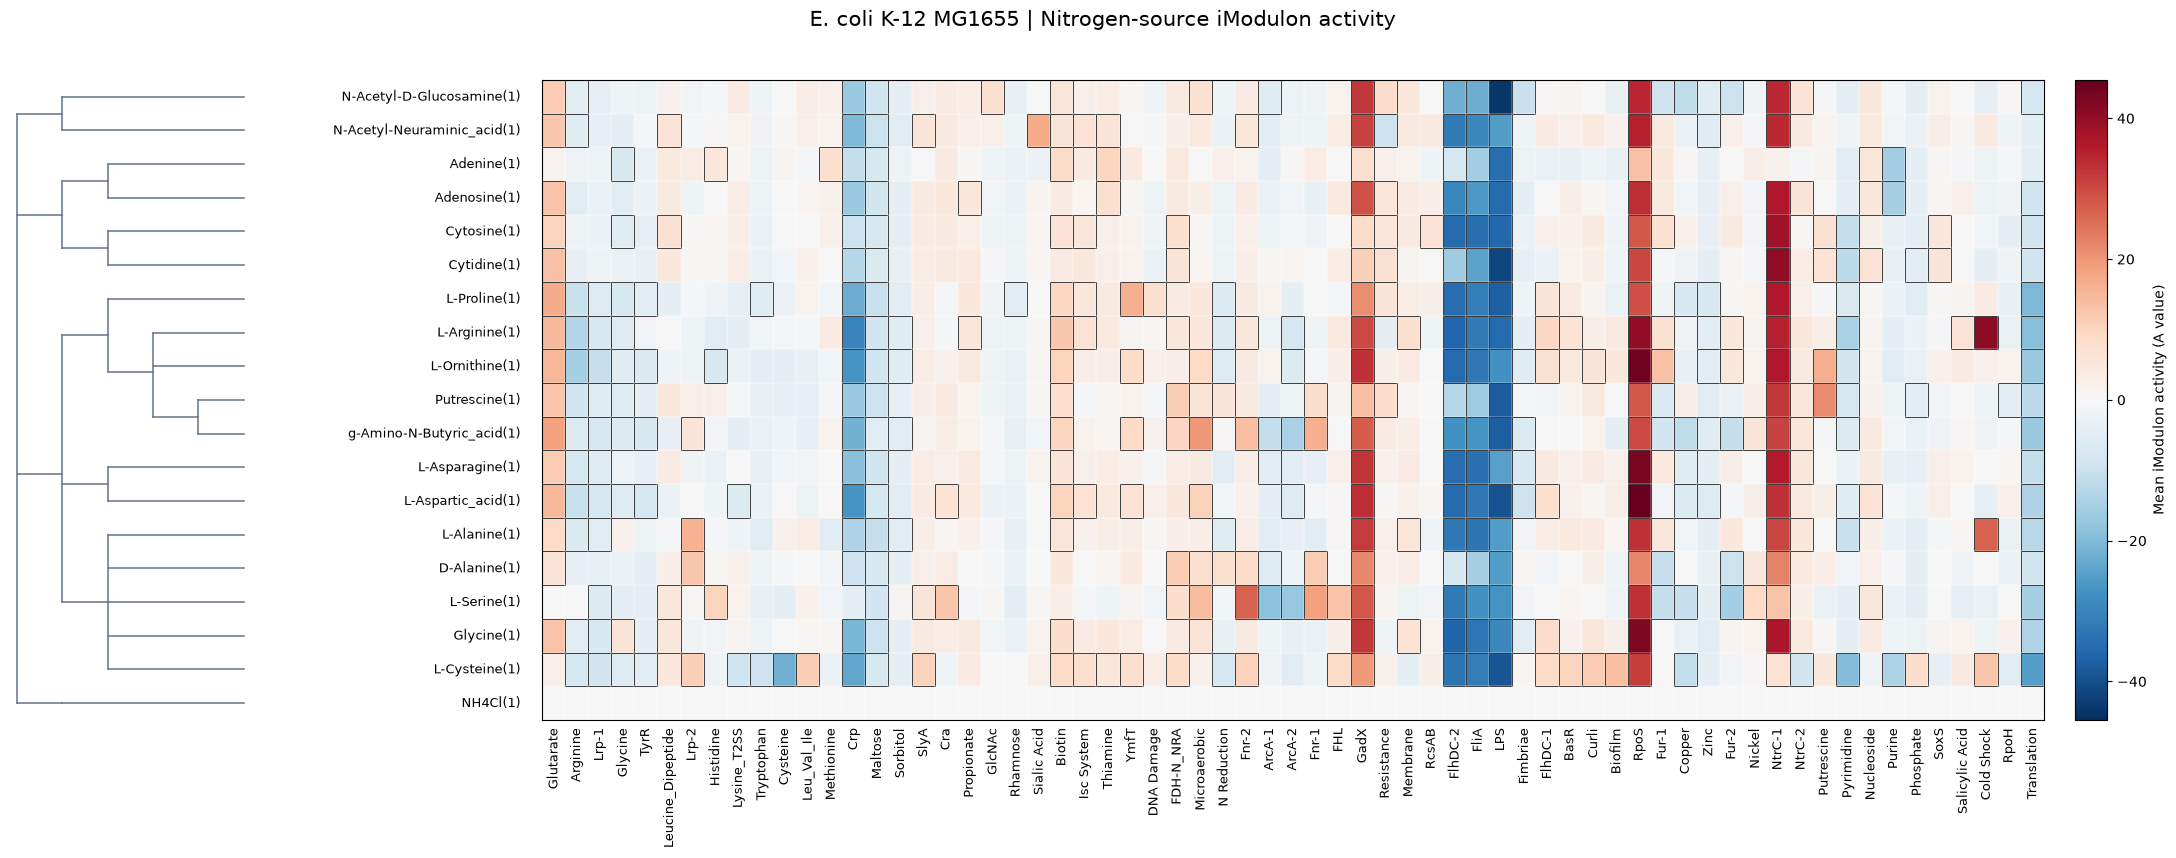

In [56]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. Define nitrogen-source metabolic hierarchy
# ============================================================

pathway_tree = {
    "Amino sugar metabolism": {
        "N-Acetyl-D-Glucosamine": {},
        "N-Acetyl-Neuraminic acid": {}
    },
    "Nucleotide metabolism": {
        "Purine metabolism": {
            "Adenine": {},
            "Adenosine": {}
        },
        "Pyrimidine metabolism": {
            "Cytosine": {},
            "Cytidine": {}
        }
    },
    "Amino acid / Polyamine metabolism": {
        "Glutamate-related metabolism": {
            "L-Proline": {},
            "Arginine / Ornithine branch": {
                "L-Arginine": {},
                "L-Ornithine": {},
                "Polyamine / GABA branch": {
                    "Putrescine": {},
                    "γ-Aminobutyric acid": {}
                }
            }
        },
        "Aspartate metabolism": {
            "L-Asparagine": {},
            "L-Aspartic acid": {}
        },
        "Pyruvate / One-carbon metabolism": {
            "L-Alanine": {},
            "D-Alanine": {},
            "L-Serine": {},
            "Glycine": {},
            "L-Cysteine": {}
        }
    },
    "Inorganic nitrogen": {
        "NH4Cl": {}
    }
}


# ============================================================
# 2. Extract leaves in tree order
# ============================================================

def get_leaves(subtree):
    leaves = []

    for name, children in subtree.items():
        if children:
            leaves.extend(get_leaves(children))
        else:
            leaves.append(name)

    return leaves


tree_leaves = get_leaves(pathway_tree)

# Match tree names to actual heatmap index
# e.g. L-Arginine -> L-Arginine(1)

name_map = {
    "γ-Aminobutyric acid": "g-Amino-N-Butyric_acid(1)",
    "N-Acetyl-D-Glucosamine": "N-Acetyl-D-Glucosamine(1)",
    "N-Acetyl-Neuraminic acid": "N-Acetyl-Neuraminic_acid(1)",
    "L-Aspartic acid": "L-Aspartic_acid(1)"
}

def match_name(name, available):
    candidates = [
        name_map.get(name, ""),
        name,
        name + "(1)",
        name.replace(" ", "_"),
        name.replace(" ", "_") + "(1)"
    ]

    for candidate in candidates:
        if candidate in available:
            return candidate

    raise ValueError(f"Cannot match nitrogen source: {name}")


nitrogen_order = [
    match_name(name, heatmap_data.index)
    for name in tree_leaves
]

# Reorder heatmap
heatmap_data = heatmap_data.loc[
    nitrogen_order,
    imodulon_order
]

values = heatmap_data.to_numpy(dtype=float)
n_rows, n_cols = values.shape


# ============================================================
# 3. Map leaf names to heatmap row positions
# ============================================================

leaf_y = {
    name: i
    for i, name in enumerate(tree_leaves)
}


def tree_depth(subtree):
    if not subtree:
        return 0

    return 1 + max(
        tree_depth(children)
        for children in subtree.values()
    )


max_depth = tree_depth(pathway_tree)


# ============================================================
# 4. Figure layout
# ============================================================

fig = plt.figure(figsize=(23, 10))

gs = GridSpec(
    1, 3,
    figure=fig,
    width_ratios=[1.5, 1.75, 10],
    wspace=0.015
)

ax_tree = fig.add_subplot(gs[0, 0])
ax_labels = fig.add_subplot(gs[0, 1], sharey=ax_tree)
ax = fig.add_subplot(gs[0, 2], sharey=ax_tree)


# ============================================================
# 5. Draw compact phylogenetic-style pathway tree
# ============================================================

tree_color = "#64748B"
tree_lw = 1.1

# Every terminal branch ends at same X
leaf_end_x = max_depth


def draw_tree(subtree, x=0):

    child_positions = []

    for name, children in subtree.items():

        if children:
            y = draw_tree(children, x + 1)
            end_x = x + 1

        else:
            y = leaf_y[name]
            end_x = leaf_end_x

        child_positions.append(y)

        # Horizontal branch
        ax_tree.plot(
            [x, end_x],
            [y, y],
            color=tree_color,
            linewidth=tree_lw
        )

    # Vertical connection
    if len(child_positions) > 1:
        ax_tree.plot(
            [x, x],
            [min(child_positions), max(child_positions)],
            color=tree_color,
            linewidth=tree_lw
        )

    return np.mean(child_positions)


draw_tree(pathway_tree)

ax_tree.set_xlim(-0.15, leaf_end_x + 0.05)
ax_tree.set_ylim(n_rows - 0.5, -0.5)
ax_tree.axis("off")


# ============================================================
# 6. Nitrogen-source labels
# ============================================================

ax_labels.set_xlim(0, 1)

for name, y in leaf_y.items():

    # Use the actual sample name
    label = match_name(name, heatmap_data.index)

    ax_labels.text(
        0.96,
        y,
        label,
        fontsize=9,
        ha="right",
        va="center"
    )

ax_labels.set_ylim(n_rows - 0.5, -0.5)
ax_labels.axis("off")


# ============================================================
# 7. Draw iModulon activity heatmap
# ============================================================

vmax = max(
    5,
    np.nanmax(np.abs(values))
)

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#eeeeee")

im = ax.imshow(
    values,
    cmap=cmap,
    vmin=-vmax,
    vmax=vmax,
    aspect="auto",
    interpolation="nearest"
)

# X-axis
ax.set_xticks(np.arange(n_cols))
ax.set_xticklabels(
    imodulon_order,
    rotation=90,
    fontsize=9
)

# Y-axis labels displayed separately
ax.set_yticks(np.arange(n_rows))
ax.set_yticklabels([])

ax.tick_params(
    axis="both",
    length=0,
    pad=6
)

# Cell boundaries
ax.set_xticks(
    np.arange(-0.5, n_cols, 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, n_rows, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=0.35
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Highlight cells with |A| >= 5
for i, j in zip(*np.where(np.abs(values) >= 5)):

    ax.add_patch(
        Rectangle(
            (j - 0.5, i - 0.5),
            1,
            1,
            fill=False,
            edgecolor="black",
            linewidth=0.7
        )
    )


# ============================================================
# 8. Colorbar
# ============================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.02
)

cbar.set_label(
    "Mean iModulon activity (A value)",
    fontsize=10
)


# ============================================================
# 9. Final styling
# ============================================================

fig.suptitle(
    "E. coli K-12 MG1655 | Nitrogen-source iModulon activity",
    fontsize=15,
    y=0.98
)

fig.subplots_adjust(
    left=0.025,
    right=0.94,
    bottom=0.27,
    top=0.91
)

plt.savefig(
    "nitrogen_pathway_activity.svg",
    bbox_inches="tight"
)

plt.savefig(
    "nitrogen_pathway_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


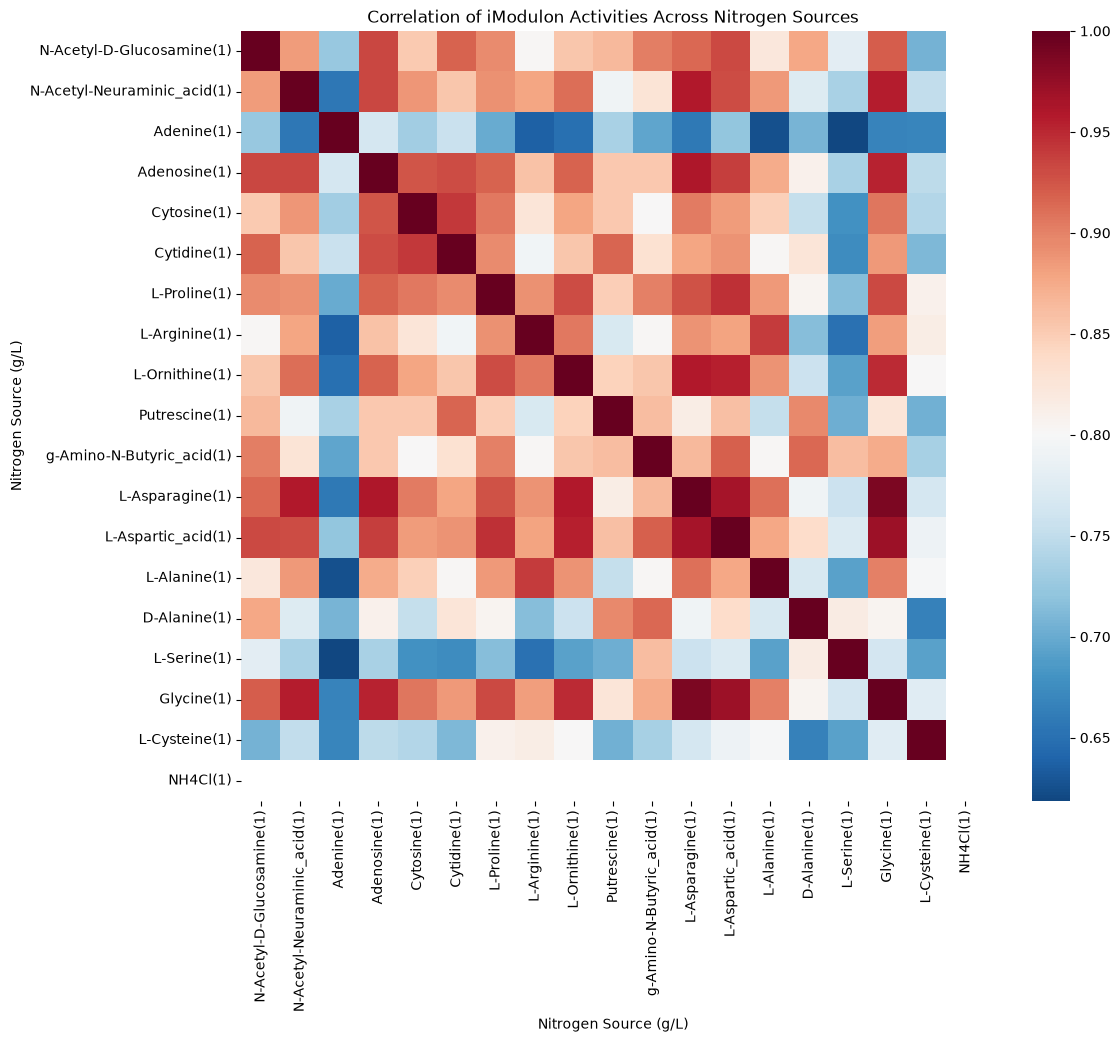

In [58]:
import seaborn as sns

corr_matrix = heatmap_data.T.corr(method="pearson")

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    cmap="RdBu_r",
    center=0.8
)

plt.title("Correlation of iModulon Activities Across Nitrogen Sources")
plt.show()

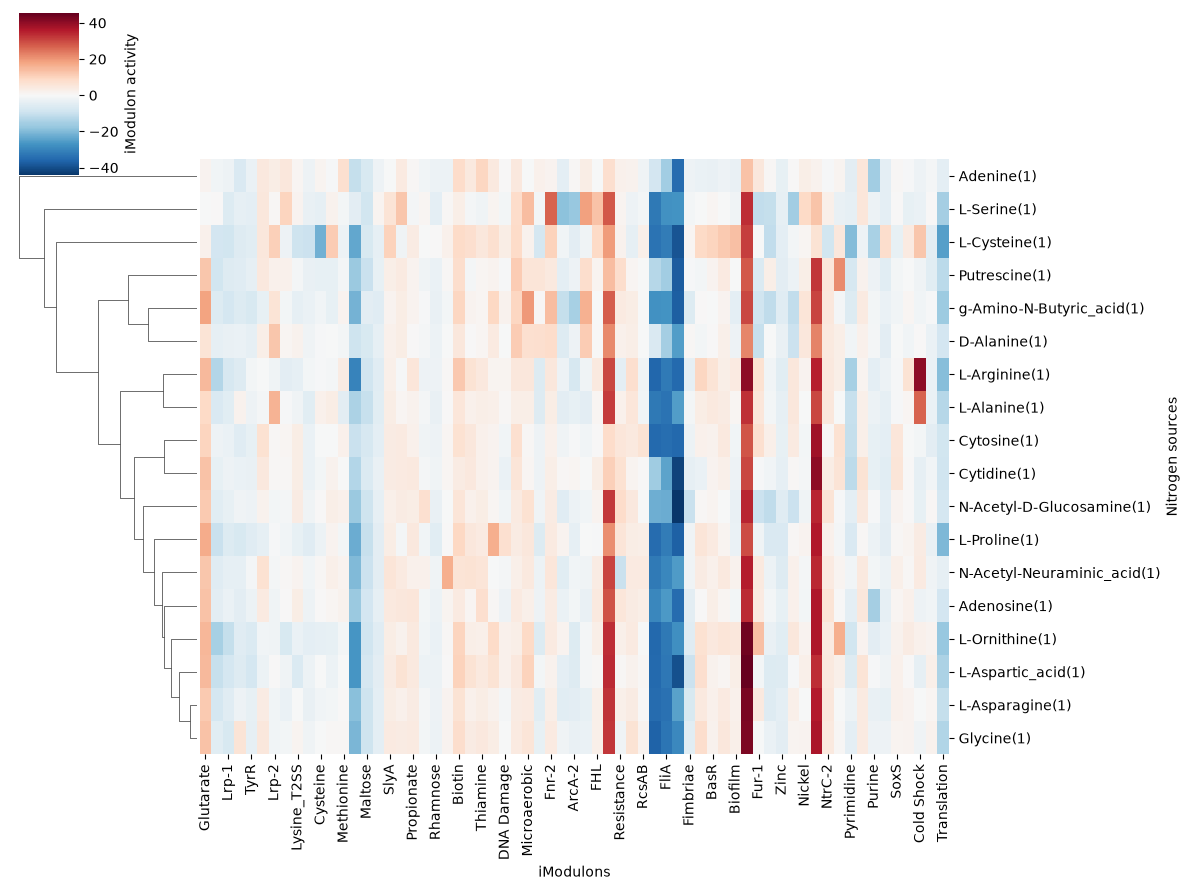

In [59]:

# A matrix: rows = iModulons, columns = samples
A_selected = heatmap_data

# Remove constant profiles (Pearson undefined)
A_selected = A_selected.loc[A_selected.std(axis=1) > 0]

g = sns.clustermap(
    A_selected,
    metric="correlation",
    method="average",
    cmap="RdBu_r",
    center=0,
    col_cluster=False,
    figsize=(12, 9),
    cbar_kws={"label": "iModulon activity"}
)

g.ax_heatmap.set_xlabel("iModulons")
g.ax_heatmap.set_ylabel("Nitrogen sources")
plt.show()

### high-plasticity/coordination genes

In [22]:
plasticity = pd.read_csv("plasticity_clean.csv")
coordination = pd.read_csv("coordination_clean.csv")

In [23]:
nitrogen_genes = plasticity[
    ["gene_id", "indegree", "nitrogen_plasticity"]
].merge(
    coordination[["gene_id", "nitrogen_coordination"]],
    on="gene_id",
    how="inner",
    validate="one_to_one")
nitrogen_genes = nitrogen_genes.merge(gene_info[["gene_id", "gene_name"]],
                                      on="gene_id", how="inner", validate="one_to_one")
nitrogen_genes.set_index("gene_id")

,indegree,nitrogen_plasticity,nitrogen_coordination,gene_name
gene_id,,,,
b0001,3.0,2.181435,0.145053,thrL
b0002,4.0,0.651174,0.161247,thrA
b0003,2.0,0.726964,0.331822,thrB
b0004,2.0,0.613485,0.282994,thrC
b0005,1.0,0.762889,0.361771,yaaX
...,...,...,...,...
b4741,2.0,0.819230,0.298215,ymiC
b4742,5.0,1.933183,0.427701,ymjE
b4777,2.0,1.348086,0.401421,mdtU


In [36]:
high_plasticity_genes = nitrogen_genes.nlargest(50, "nitrogen_plasticity")
high_coordination_genes = nitrogen_genes.nlargest(50, "nitrogen_coordination")
common_genes = list(set(high_coordination_genes["gene_id"].to_list()) & set(high_plasticity_genes["gene_id"].to_list()))
common_genes

['b3525', 'b1742', 'b1194', 'b1259', 'b1440', 'b1932']

In [25]:

for gene in common_genes:
    if gene in gene_modulon_dict.keys():
        print(f"{gene}:{gene_modulon_dict[gene]}")

b1082:{'FlhDC-2', 'FliA'}
b3525:{'FliA'}
b4002:{'NtrC-1', 'BasR'}
b4110:{'FliA'}
b1897:{'RpoS'}
b1083:{'FliA'}
b1947:{'FlhDC-2'}
b4060:{'Crp'}
b1484:{'NtrC-1'}
b3362:{'RpoS'}
b1485:{'NtrC-1'}
b1259:{'RpoS'}
b1443:{'NtrC-1'}
b2672:{'UC-9', 'RpoS'}
b1161:{'LPS'}
b1440:{'NtrC-1'}
b3361:{'RpoS'}
b2127:{'RpoS'}
b2131:{'RpoS'}
b1188:{'RpoS'}
b1937:{'FlhDC-2'}
b1194:{'FliA'}
b1945:{'FlhDC-2'}
b2129:{'RpoS'}
b3269:{'NtrC-1'}
b1932:{'NtrC-1'}
b3448:{'RpoS'}
b1646:{'RpoS'}
b3024:{'RpoS', 'TyrR'}
b1889:{'FliA'}
b1742:{'FliA'}
b1783:{'RpoS'}
b0485:{'GadX', 'RpoS'}
b4149:{'RpoS'}
b1946:{'FlhDC-2'}
b0486:{'GadX'}
b0696:{'Potassium'}


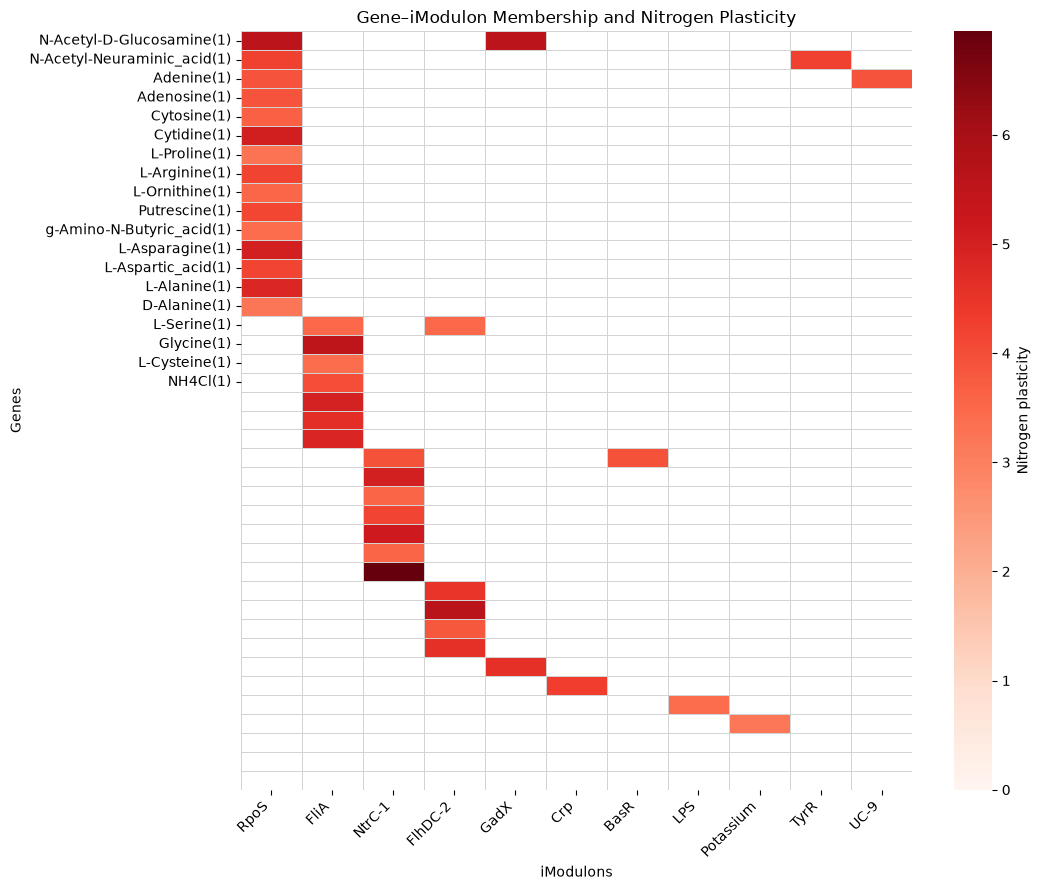

In [26]:
# Map gene_id to gene_name
gene_name_map = nitrogen_genes.set_index("gene_id")["gene_name"]

# Replace heatmap row labels
gene_labels = [
    gene_name_map.get(gene, gene)
    for gene in heatmap_data.index
]

# Selected genes
selected_genes = common_genes

# Retrieve gene-level plasticity
nitrogen_plasticity_values = (
    nitrogen_genes.set_index("gene_id")["nitrogen_plasticity"]
)

# Associated iModulons
modules = sorted(set().union(
    *(gene_modulon_dict.get(gene, set()) for gene in selected_genes)
))

# Gene × iModulon heatmap
heatmap_data = pd.DataFrame(
    {
        module: [
            nitrogen_plasticity_values.loc[gene]
            if module in gene_modulon_dict.get(gene, set())
            else float("nan")
            for gene in selected_genes
        ]
        for module in modules
    },
    index=selected_genes
)

# Sort columns by number of genes
heatmap_data = heatmap_data[
    heatmap_data.notna().sum().sort_values(ascending=False).index
]

# Sort rows by their primary iModulon
heatmap_data = heatmap_data.sort_values(
    by=list(heatmap_data.columns),
    key=lambda col: col.isna(),
    kind="stable"
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    heatmap_data,
    cmap="Reds",
    vmin=0,
    linewidths=0.5,
    linecolor="lightgray",
    yticklabels=gene_labels,
    cbar_kws={"label": "Nitrogen plasticity"}
)

plt.xlabel("iModulons")
plt.ylabel("Genes")
plt.title("Gene–iModulon Membership and Nitrogen Plasticity")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

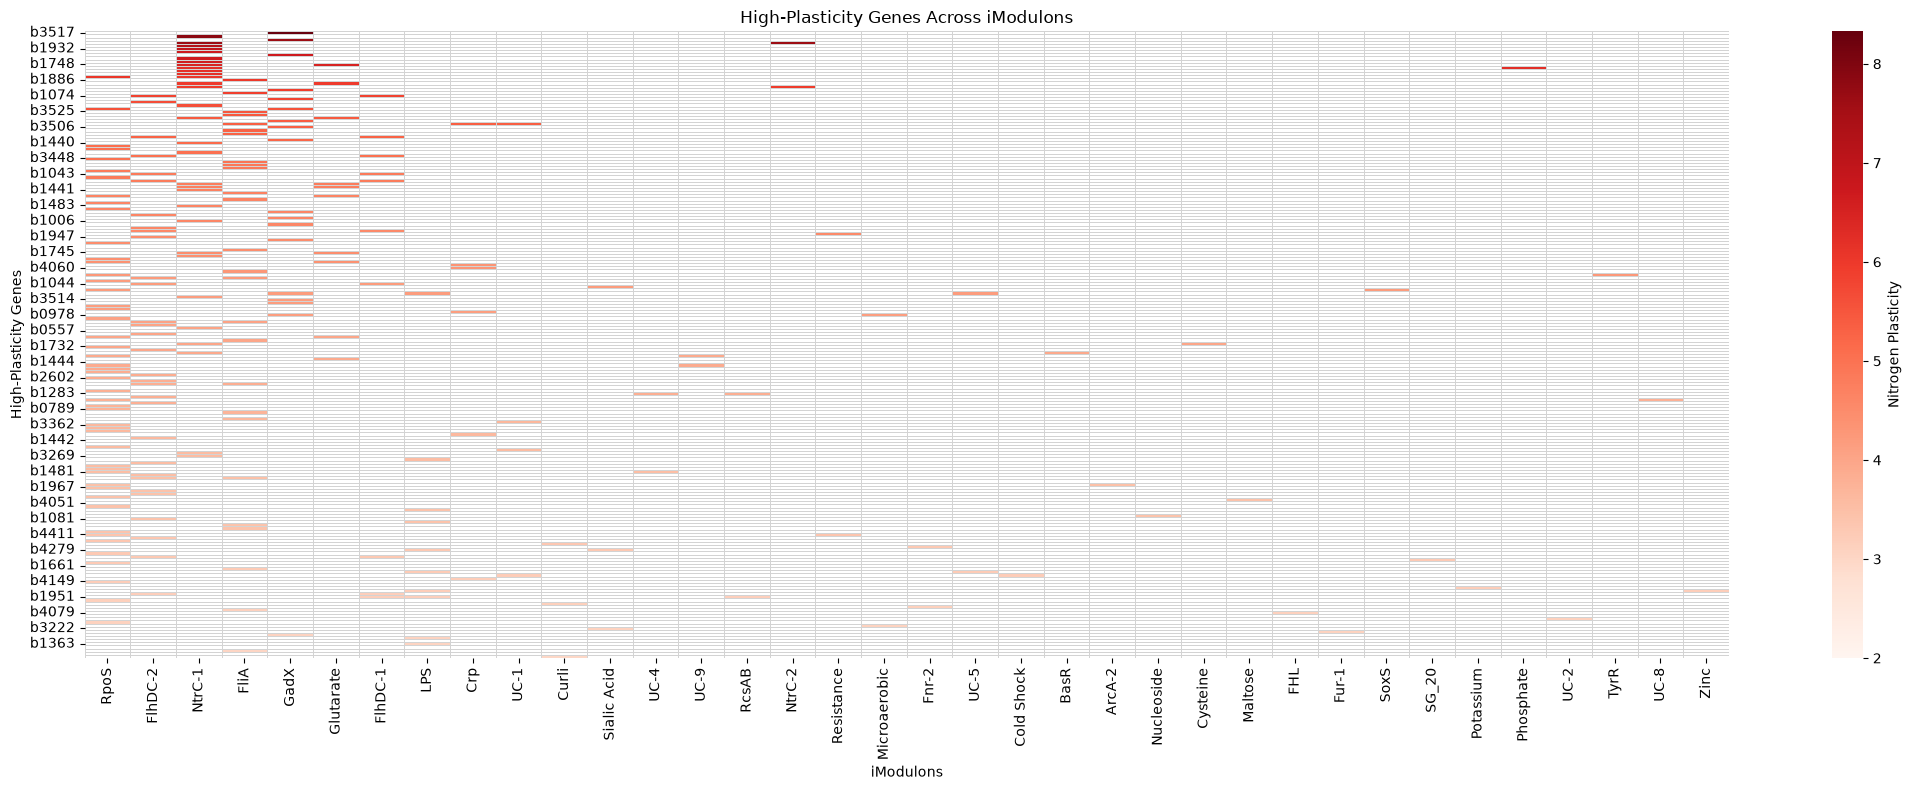

In [27]:
# 1. High-plasticity genes
high_genes = high_plasticity_genes["gene_id"].tolist()

# Gene-level nitrogen plasticity
nitrogen_plasticity_values = high_plasticity_genes.set_index(
    "gene_id"
)["nitrogen_plasticity"]

# 2. Find all associated iModulons
modules = sorted(set().union(
    *(gene_modulon_dict.get(gene, set()) for gene in high_genes)
))

# Create heatmap directly from the dictionary
heatmap_data = pd.DataFrame(
    {
        module: [
            nitrogen_plasticity_values.loc[gene]
            if module in gene_modulon_dict.get(gene, set())
            else float("nan")
            for gene in high_genes
        ]
        for module in modules
    },
    index=high_genes
)

# 4. Sort iModulons by number of high-plasticity genes
heatmap_data = heatmap_data[
    heatmap_data.notna().sum().sort_values(ascending=False).index
]

# 5. Plot
plt.figure(figsize=(max(10, len(modules) * 0.6), 8))

sns.heatmap(
    heatmap_data,
    cmap="Reds",
    vmin=2,
    linewidths=0.5,
    linecolor="lightgray",
    cbar_kws={"label": "Nitrogen Plasticity"}
)

plt.xlabel("iModulons")
plt.ylabel("High-Plasticity Genes")
plt.title("High-Plasticity Genes Across iModulons")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

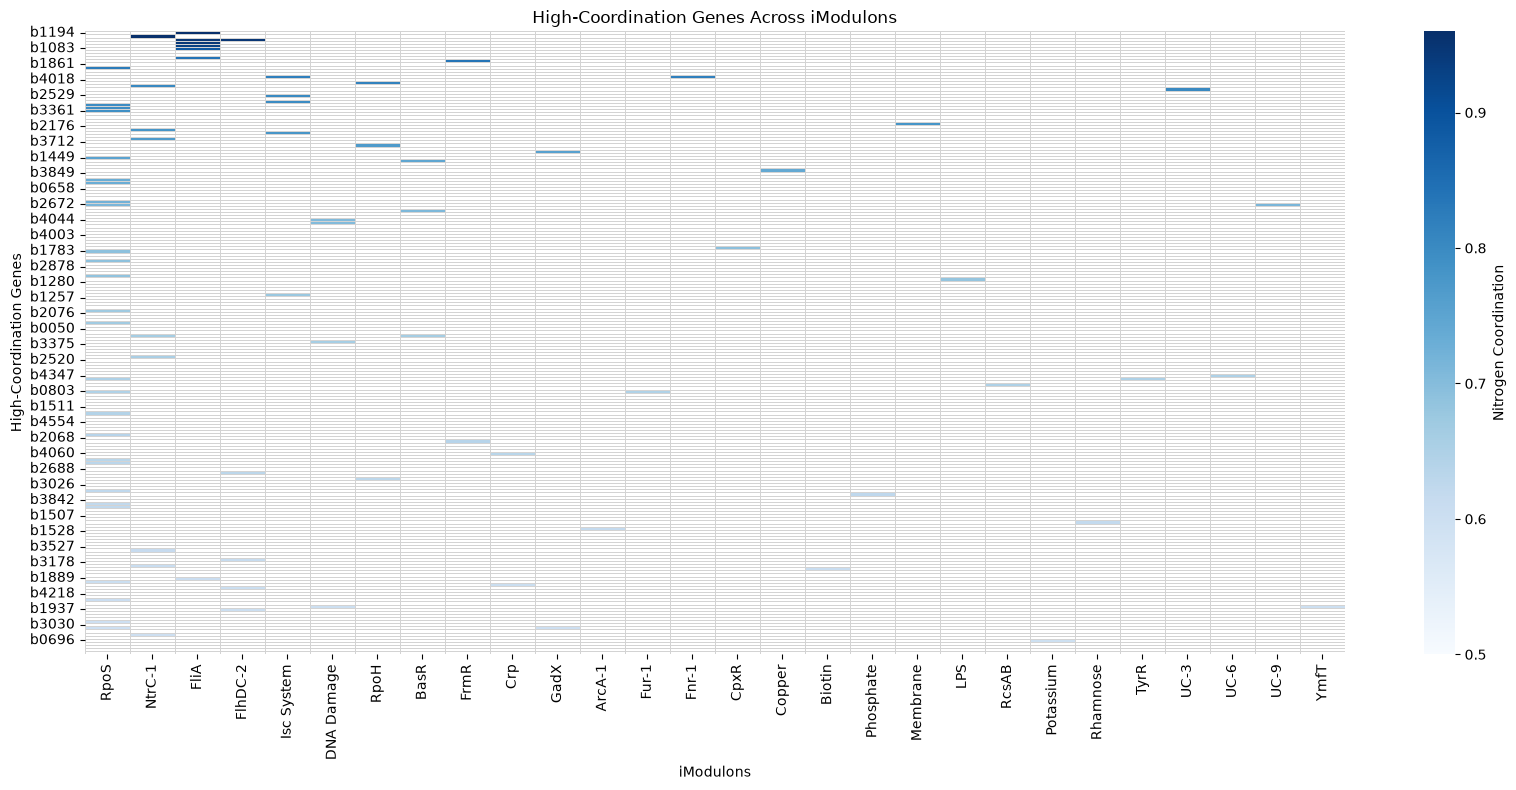

In [28]:

high_genes = high_coordination_genes["gene_id"].tolist()

coordination = high_coordination_genes.set_index(
    "gene_id"
)["nitrogen_coordination"]

# Find associated iModulons
modules = sorted(set().union(
    *(gene_modulon_dict.get(gene, set()) for gene in high_genes)
))

# Gene × iModulon, colored by coordination
heatmap_data = pd.DataFrame(
    {
        module: [
            coordination.loc[gene]
            if module in gene_modulon_dict.get(gene, set())
            else float("nan")
            for gene in high_genes
        ]
        for module in modules
    },
    index=high_genes
)

# Sort iModulons by number of high-coordination genes
heatmap_data = heatmap_data[
    heatmap_data.notna().sum().sort_values(ascending=False).index
]

plt.figure(figsize=(max(10, len(modules) * 0.6), 8))

sns.heatmap(
    heatmap_data,
    cmap="Blues",
    vmin=0.5,
    linewidths=0.5,
    linecolor="lightgray",
    cbar_kws={"label": "Nitrogen Coordination"}
)

plt.xlabel("iModulons")
plt.ylabel("High-Coordination Genes")
plt.title("High-Coordination Genes Across iModulons")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### iModulons' plasticity and coordiantion

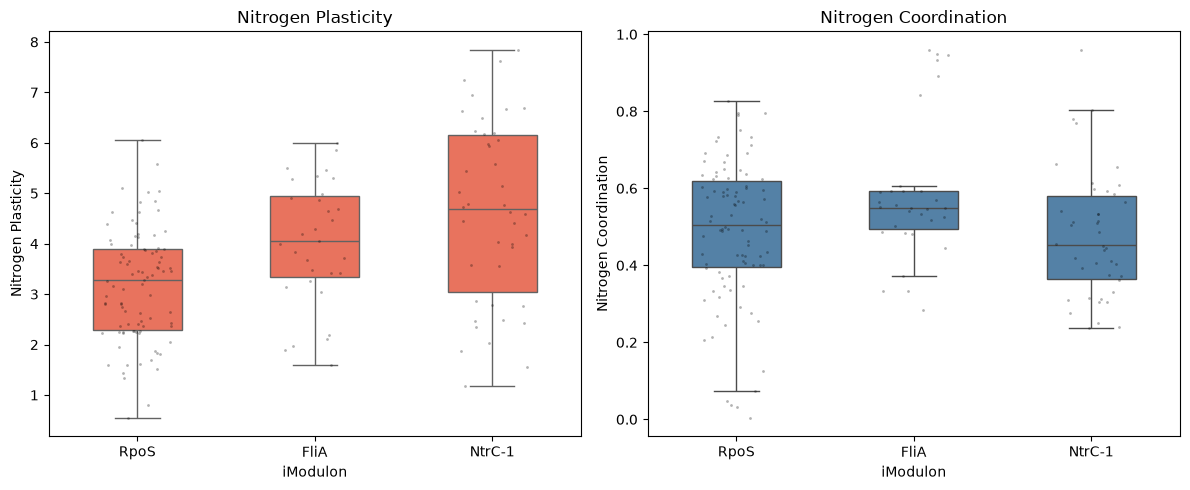

          n_plasticity  median_plasticity  n_coordination  \
iModulon                                                    
FliA                31              4.063              31   
NtrC-1              42              4.680              42   
RpoS                90              3.277              90   

          median_coordination  mean_coordination  
iModulon                                          
FliA                    0.550              0.588  
NtrC-1                  0.453              0.480  
RpoS                    0.506              0.488  


In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select iModulons
selected_modules = ["RpoS", "FliA", "NtrC-1"]

# Gene information
gene_info = nitrogen_genes.copy()

# Handle gene_id whether it is a column or index
if "gene_id" not in gene_info.columns:
    gene_info = gene_info.reset_index()

# Create long-format dataframe
module_data = []

for module in selected_modules:
    genes = [
        gene
        for gene in gene_info["gene_id"]
        if module in gene_modulon_dict.get(gene, set())
    ]

    subset = gene_info[
        gene_info["gene_id"].isin(genes)
    ].copy()

    subset["iModulon"] = module
    module_data.append(subset)

module_data = pd.concat(module_data, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = [
    ("nitrogen_plasticity", "Nitrogen Plasticity", "tomato"),
    ("nitrogen_coordination", "Nitrogen Coordination", "steelblue")
]

for ax, (metric, title, color) in zip(axes, metrics):

    sns.boxplot(
        data=module_data,
        x="iModulon",
        y=metric,
        order=selected_modules,
        color=color,
        showfliers=False,
        width=0.5,
        ax=ax
    )

    sns.stripplot(
        data=module_data,
        x="iModulon",
        y=metric,
        order=selected_modules,
        color="black",
        alpha=0.3,
        size=2,
        jitter=0.2,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("iModulon")
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

summary = module_data.groupby("iModulon").agg(
    n_plasticity=("nitrogen_plasticity", "count"),
    median_plasticity=("nitrogen_plasticity", "median"),
    n_coordination=("nitrogen_coordination", "count"),
    median_coordination=("nitrogen_coordination", "median"),
    mean_coordination=("nitrogen_coordination", "mean")
)

print(summary.round(3))

### Adenine Adenosine
Adenine (pmg_wt_131, pmg_wt_132)

Adenosine (pmg_wt_133, pmg_wt_134)


In [30]:
plasticity_clean = pd.read_csv("plasticity_clean.csv")
tpm = pd.read_csv("precise_mg1655-log_tpm.csv")
Ad_df = plasticity_clean[["gene_id", "indegree"]].copy()
Ad_df["Adenine"] = tpm[["pmg_wt_131", "pmg_wt_132"]].mean(axis=1)
Ad_df["Adenosine"] = tpm[["pmg_wt_133", "pmg_wt_134"]].mean(axis=1)
Ad_df.set_index("gene_id")
Ad_df["iModulon"] = np.nan

for gene in Ad_df["gene_id"]:
    if gene in gene_modulon_dict.keys():
        Ad_df["iModulon"] = Ad_df["gene_id"].map(gene_modulon_dict)


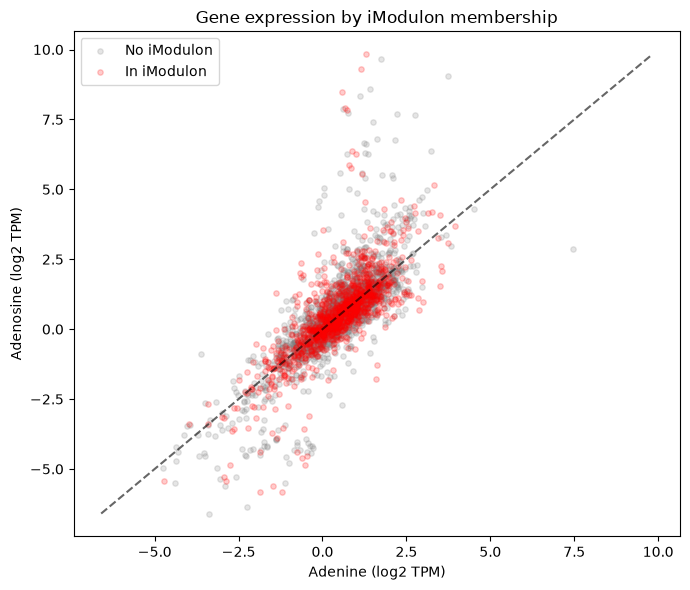

In [31]:

Ad_df["has_iModulon"] = Ad_df["iModulon"].apply(
    lambda x: (
        len(x) > 0 if isinstance(x, (set, list, tuple))
        else pd.notna(x)
    )
)

plt.figure(figsize=(7, 6))

# Genes without iModulon
mask = ~Ad_df["has_iModulon"]

plt.scatter(
    Ad_df.loc[mask, "Adenine"],
    Ad_df.loc[mask, "Adenosine"],
    color="gray",
    label="No iModulon",
    s=15,
    alpha=0.2
)

# Genes with iModulon
mask = Ad_df["has_iModulon"]

plt.scatter(
    Ad_df.loc[mask, "Adenine"],
    Ad_df.loc[mask, "Adenosine"],
    color="red",
    label="In iModulon",
    s=15,
    alpha=0.2
)

# y = x
vmin = Ad_df[["Adenine", "Adenosine"]].min().min()
vmax = Ad_df[["Adenine", "Adenosine"]].max().max()

plt.plot([vmin, vmax], [vmin, vmax], "k--", alpha=0.6)

plt.xlabel("Adenine (log2 TPM)")
plt.ylabel("Adenosine (log2 TPM)")
plt.title("Gene expression by iModulon membership")

plt.legend()
plt.tight_layout()
plt.show()

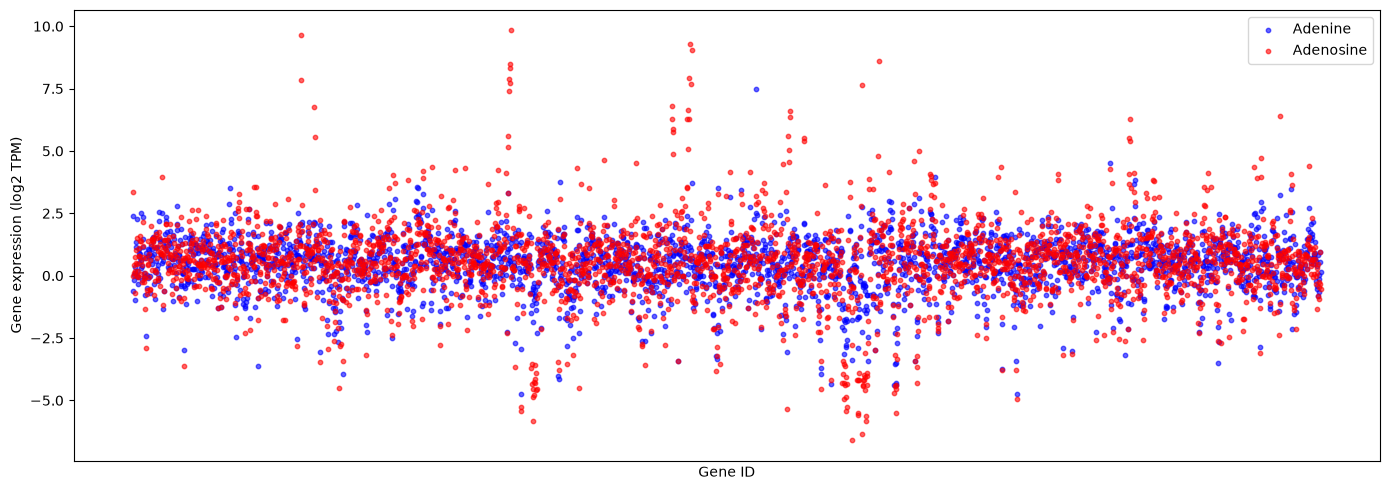

In [32]:
plt.figure(figsize=(14, 5))

plt.scatter(
    Ad_df["gene_id"],
    Ad_df["Adenine"],
    color="blue",
    label="Adenine",
    s=10,
    alpha=0.6
)

plt.scatter(
    Ad_df["gene_id"],
    Ad_df["Adenosine"],
    color="red",
    label="Adenosine",
    s=10,
    alpha=0.6
)

plt.xlabel("Gene ID")
plt.ylabel("Gene expression (log2 TPM)")
plt.legend()
plt.xticks([])
plt.tight_layout()
plt.show()

In [33]:
Ad_df["diff"] = Ad_df["Adenine"] - Ad_df["Adenosine"]
Ad_df["abs_diff"] = Ad_df["diff"].abs()
top_genes = (
    Ad_df
    .sort_values("abs_diff", ascending=False))

print(top_genes.head(30)["gene_id"].to_list())

['b1450', 'b2156', 'b0648', 'b1449', 'b1446', 'b2155', 'b1448', 'b2909', 'b0651', 'b1447', 'b1445', 'b2154', 'b2162', 'b2553', 'b2152', 'b2163', 'b2556', 'b2151', 'b2077', 'b2085', 'b1444', 'b3781', 'b2153', 'b2091', 'b2078', 'b2824', 'b2908', 'b2551', 'b2841', 'b0720']


In [34]:
for gene in top_genes.head(50)["gene_id"].to_list():
    if gene in gene_modulon_dict.keys():
        print(f"{gene}:{gene_modulon_dict[gene]}")
    else:
        print(f"{gene} no iModulon")
        pass

b1450:{'RpoS'}
b2156:{'Lysine/T2SS', 'UC-3'}
b0648 no iModulon
b1449:{'RpoS'}
b1446 no iModulon
b2155:{'Fur-1'}
b1448 no iModulon
b2909 no iModulon
b0651:{'Crp'}
b1447 no iModulon
b1445 no iModulon
b2154 no iModulon
b2162 no iModulon
b2553:{'UC-9'}
b2152 no iModulon
b2163 no iModulon
b2556 no iModulon
b2151:{'Galactose'}
b2077 no iModulon
b2085:{'EvgA', 'LPS'}
b1444 no iModulon
b3781 no iModulon
b2153 no iModulon
b2091:{'Crp'}
b2078 no iModulon
b2824 no iModulon
b2908 no iModulon
b2551 no iModulon
b2841:{'Arabinose'}
b0720 no iModulon
b2428 no iModulon
b3335 no iModulon
b2542 no iModulon
b2806 no iModulon
b0721:{'ArcA-2', 'Crp', 'ArcA-1'}
b1536:{'RpoS'}
b2552 no iModulon
b2843:{'UxuR'}
b3778 no iModulon
b2825 no iModulon
b2826 no iModulon
b1534:{'Lrp-2'}
b2840:{'Arabinose'}
b1535:{'CpxR'}
b1538 no iModulon
b2827 no iModulon
b2833 no iModulon
b2079 no iModulon
b2828 no iModulon
b1537 no iModulon


### Functional diversity

For the targets of TF, the functional (COG) diversity: Shannon entropy
$$H=-\sum_{i=1}^{K}p_i\ln p_i$$

In [ ]:
nitrogen_genes["cog"] = gene_info["cog"].copy()

,gene_id,indegree,nitrogen_plasticity,nitrogen_coordination,gene_name,cog
0,b0001,3.0,2.181435,0.145053,thrL,No COG annotation
1,b0002,4.0,0.651174,0.161247,thrA,Amino acid transport and metabolism
2,b0003,2.0,0.726964,0.331822,thrB,Nucleotide transport and metabolism
3,b0004,2.0,0.613485,0.282994,thrC,Amino acid transport and metabolism
4,b0005,1.0,0.762889,0.361771,yaaX,Function unknown
...,...,...,...,...,...,...
2910,b4741,2.0,0.819230,0.298215,ymiC,Cell wall\/membrane\/envelope biogenesis
2911,b4742,5.0,1.933183,0.427701,ymjE,"Replication, recombination and repair"
2912,b4777,2.0,1.348086,0.401421,mdtU,"Translation, ribosomal structure and biogenesis"
2913,b4782,1.0,1.677630,0.039506,pssL,Function unknown


In [60]:
A_nitrogen_binary.to_csv("A_N_binary.csv")